In [31]:
"""
Reproduce the bar chart from the manuscript.
"""

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import pingouin as pg
from scipy.stats import t as t_dist
from scipy import stats
import matplotlib.patches as patches
import seaborn as sns
# Paths relative to this script
# ROOT = Path.cwd()
# DATA = ROOT / "figures"
# FIGURES = ROOT / "figures"
# FIGURES.mkdir(exist_ok=True)
ROOT = Path.cwd()
DATA = ROOT / "./../DATA"
FIGURES = ROOT / "./../figures"
colors = [(0, 48, 73),(214, 40, 40),(247, 127, 0),(252, 191, 73),(234, 226, 183),(148, 210, 189),
          (10, 147, 150),(17, 130, 0),]
colorz = []
for x in colors:
    colorz.append((x[0]/255,x[1]/255,x[2]/255))
    
colors1 = [(0, 48, 73),(214, 40, 40),(0, 48, 73),(214, 40, 40),(0, 48, 73),(214, 40, 40),
          (0, 48, 73),(214, 40, 40),]
colorz1 = []
for x in colors1:
    colorz1.append((x[0]/255,x[1]/255,x[2]/255))
    
def simple_beeswarm2(y, nbins=None, width=1.):
    """
    Returns x coordinates for the points in ``y``, so that plotting ``x`` and
    ``y`` results in a bee swarm plot.
    """
    y = np.asarray(y)
    if nbins is None:
        # nbins = len(y) // 6
        nbins = np.ceil(len(y) / 6).astype(int)
    # Get upper bounds of bins
    x = np.zeros(len(y))
    nn, ybins = np.histogram(y, bins=nbins)
    nmax = nn.max()
    #Divide indices into bins
    ibs = []#np.nonzero((y>=ybins[0])*(y<=ybins[1]))[0]]
    for ymin, ymax in zip(ybins[:-1], ybins[1:]):
        i = np.nonzero((y>ymin)*(y<=ymax))[0]
        ibs.append(i)
    # Assign x indices
    dx = width / (nmax // 2)
    for i in ibs:
        yy = y[i]
        if len(i) > 1:
            j = len(i) % 2
            i = i[np.argsort(yy)]
            a = i[j::2]
            b = i[j+1::2]
            x[a] = (0.5 + j / 3 + np.arange(len(b))) * dx
            x[b] = (0.5 + j / 3 + np.arange(len(b))) * -dx
    return x    

def dunnett_test(samples, control, alternative='two-sided'):
    """
    Manual implementation of Dunnett's test for comparing multiple 
    treatment groups against a single control group.
    
    Parameters:
    -----------
    samples : list of array_like
        List of treatment group samples
    control : array_like
        Control group sample
    alternative : str
        'two-sided', 'less', or 'greater'
    
    Returns:
    --------
    statistic : ndarray
        Test statistics for each treatment vs control
    pvalues : ndarray
        P-values for each treatment vs control
    """
    
    # Convert to arrays
    control = np.asarray(control)
    samples = [np.asarray(sample) for sample in samples]
    
    n_groups = len(samples) + 1  # +1 for control
    n_control = len(control)
    n_treatments = [len(s) for s in samples]
    
    # Group means
    mean_control = np.mean(control)
    means_treatments = [np.mean(s) for s in samples]
    
    # Variances for each group
    var_control = np.var(control, ddof=1)
    vars_treatments = [np.var(s, ddof=1) for s in samples]
    
    # Pooled variance (assuming equal variance across groups)
    # That's a key assumption of Dunnett's test
    all_values = np.concatenate([control] + samples)
    grand_mean = np.mean(all_values)
    
    # Calculate Mean Square Error (within-group variance)
    ss_within = 0
    df_within = 0
    for group in [control] + samples:
        ss_within += np.sum((group - np.mean(group))**2)
        df_within += len(group) - 1
    
    ms_within = ss_within / df_within
    
    # Calculate standard error for each comparison
    # SE = sqrt(MS_within * (1/n_control + 1/n_treatment))
    se_values = []
    for n_treat in n_treatments:
        se = np.sqrt(ms_within * (1/n_control + 1/n_treat))
        se_values.append(se)
    
    # Calculate t-statistics
    t_stats = []
    for mean_treat, se in zip(means_treatments, se_values):
        t_stat = (mean_treat - mean_control) / se
        t_stats.append(t_stat)
    
    # Critical values and p-values
    # For Dunnett's test, we need the t-distribution with df = df_within
    # and adjust for multiple comparisons
    
    if alternative == 'two-sided':
        # For two-sided test
        pvalues = [2 * (1 - t_dist.cdf(abs(t), df=df_within)) 
                   for t in t_stats]
    elif alternative == 'less':
        pvalues = [t_dist.cdf(t, df=df_within) for t in t_stats]
    elif alternative == 'greater':
        pvalues = [1 - t_dist.cdf(t, df=df_within) for t in t_stats]
    else:
        raise ValueError("alternative must be 'two-sided', 'less', or 'greater'")
    
    # Bonferroni correction for multiple comparisons (conservative)
    # For proper Dunnett, you'd use the specialized distribution,
    # but Bonferroni is a safe approximation
    pvalues_bonferroni = np.array(pvalues) * n_groups
    pvalues_bonferroni = np.minimum(pvalues_bonferroni, 1.0)
    
    return np.array(t_stats), pvalues_bonferroni

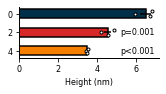

In [32]:
Rawdata = DATA / "Fig2D_data.parquet"
df_all = pd.read_parquet(Rawdata)
df_all['Average value'] = df_all['Average value'].astype(float)

# Separate the normal and 'nm' rows
normal = df_all[~df_all['label'].str.endswith('nm')].set_index('label')
nm     = df_all[df_all['label'].str.endswith('nm')].copy()
nm['label'] = nm['label'].str.replace('nm', '', regex=False)
nm = nm.set_index('label')
diff = normal['Average value'] - nm['Average value']
df = pd.DataFrame({'label': normal.index,
                   'normal': normal['Average value'],
                   'nm': nm['Average value'],
                   'difference': normal['Average value'] - nm['Average value']
                   }).reset_index(drop=True)

df['label'] = df['label'].str[:-1]
means, sems = df.groupby('label')['difference'].mean(), df.groupby('label')['difference'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'G2']['difference'],
                                  df[df['label'] == 'G4']['difference'],], 
                                  df[df['label'] == 'G0']['difference'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,0.9375))
people  = ('0','2','4',)
y_pos = np.arange(len(people))
ax.barh(y_pos, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'G0']['difference'], width=0.25)
ax.plot(df[df['label'] == 'G0']['difference'],x1, '.', label = 'D',color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'G2']['difference'], width=0.25)
ax.plot(df[df['label'] == 'G2']['difference'],x2+1,  '.', label = 'C9',color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'G4']['difference'], width=0.25)
ax.plot(df[df['label'] == 'G4']['difference'],x3+2,  '.', label = 'aH',color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Height (nm)',fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [6,6], 0.1
label1 = f"p={p_values[0]:.3f}" ### p=0.004581 tt, p-dunnett=0.0013
label2 = r"p<0.001" ### p=0.000455 tt, p-dunnett=0.0001
ax.text(pvp[0] + pad,1, label1, fontsize=8, va="center", ha="center")
ax.text(pvp[1] + pad,2, label2, fontsize=8, va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# FIGURES = ROOT / "figures"
# outfile = FIGURES / "figure2D.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

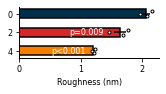

In [33]:
Rawdata = DATA / "Fig2D_data.parquet"
df_all = pd.read_parquet(Rawdata)

df_all = df_all[df_all['label'].isin(['G01','G02','G03','G21','G22','G23','G41','G42','G43',])]
df_all['label'] = df_all['label'].str[:-1]
df = df_all[['Mean roughness (Sa)','label']].reset_index(drop=True)
df['Mean roughness (Sa)'] = df['Mean roughness (Sa)'].astype(float)
means = df.groupby('label')['Mean roughness (Sa)'].mean()
sems = df.groupby('label')['Mean roughness (Sa)'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'G2']['Mean roughness (Sa)'],
                                  df[df['label'] == 'G4']['Mean roughness (Sa)'],], 
                                  df[df['label'] == 'G0']['Mean roughness (Sa)'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,0.9375))
people, y_pos = ('0','2','4',), [0,1,2]
ax.barh(people, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'G0']['Mean roughness (Sa)'], width=0.25)
ax.plot(df[df['label'] == 'G0']['Mean roughness (Sa)'],x1, '.', label = 'D',
        color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'G2']['Mean roughness (Sa)'], width=0.25)
ax.plot(df[df['label'] == 'G2']['Mean roughness (Sa)'],x2+1,  '.', label = 'C9',
        color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'G4']['Mean roughness (Sa)'], width=0.25)
ax.plot(df[df['label'] == 'G4']['Mean roughness (Sa)'],x3+2,  '.', label = 'aH',
        color ='w',markeredgecolor='black')
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Roughness (nm)',fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [0.9,0.6], 0.2 
label1 = f"p={p_values[0]:.3f}" ### p=0.017088 tt, p-dunnett=0.0093
label2 = r"p<0.001" ### p=0.000133 tt, p-dunnett=0.0002
ax.text(pvp[0] + pad,1, label1, fontsize=8,color='w', va="center", ha="center")
ax.text(pvp[1] + pad,2, label2, fontsize=8, color='w', va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2E.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

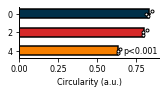

In [34]:
Rawdata = DATA / "Fig2F_data.parquet"
df = pd.read_parquet(Rawdata)

df = df.groupby('label')['Circ.'].describe().T
df = pd.DataFrame([(group, val) for group, vals in df.items() for val in vals[1:2]],
                  columns=['group', 'value'])
df['group'] = df['group'].str[1:-1]
means, sems = df.groupby('group')['value'].mean(), df.groupby('group')['value'].sem()

t_stats, p_values = dunnett_test([df[df['group'] == '2']['value'],df[df['group'] == '4']['value'],], 
                                  df[df['group'] == '0']['value'], alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,0.9375))
people = ('0','2','4',)
y_pos = [0,1,2,]
ax.barh(y_pos, means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),linewidth=1.5,
        height=0.5)
x1 = simple_beeswarm2(df[df['group'] == '0']['value'], width=0.25)
ax.plot(df[df['group'] == '0']['value'],x1, '.', color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['group'] == '2']['value'], width=0.25)
ax.plot(df[df['group'] == '2']['value'],x2+1,  '.', color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['group'] == '4']['value'], width=0.25)
ax.plot(df[df['group'] == '4']['value'],x3+2,  '.', color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Circularity (a.u.)',fontsize=8)
# plt.xlim(2000, 17450)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [1,0.98],-0.2
label1 = r"ns" ### p=1.362760e-01 tt, p-dunnet=0.8913, p-dunnet_triplicate=0.16446
label2 = r"p<0.001" ### p=9.759129e-10 tt, p-dunnet=0.0000, p-dunnet_triplicate=0.00001
# ax.text(pvp[0] + pad,1, label1, fontsize=8, va="center", ha="center")
ax.text(pvp[1] + pad,2, label2, fontsize=8, va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2F.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

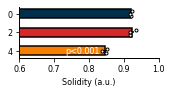

In [35]:
Rawdata = DATA / "Fig2F_data.parquet"
df = pd.read_parquet(Rawdata)

df = df.groupby('label')['Solidity'].describe().T
df = pd.DataFrame([(group, val) for group, vals in df.items() for val in vals[1:2]],
                  columns=['group', 'value'])
df['group'] = df['group'].str[1:-1]
means, sems = df.groupby('group')['value'].mean(), df.groupby('group')['value'].sem()

t_stats, p_values = dunnett_test([df[df['group'] == '2']['value'],df[df['group'] == '4']['value'],], 
                                  df[df['group'] == '0']['value'], alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,0.9375))
people, y_pos = ('0','2','4',), [0,1,2,]
ax.barh(y_pos, means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),linewidth=1.5,
        height=0.5)
x1 = simple_beeswarm2(df[df['group'] == '0']['value'], width=0.25)
ax.plot(df[df['group'] == '0']['value'],x1, '.', color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['group'] == '2']['value'], width=0.25)
ax.plot(df[df['group'] == '2']['value'],x2+1,  '.', color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['group'] == '4']['value'], width=0.25)
ax.plot(df[df['group'] == '4']['value'],x3+2,  '.', color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Solidity (a.u.)',fontsize=8)
plt.xlim(0.6, 1)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [1,0.78], 0
label2 = r"p<0.001" ### p=0.000003 tt, p-dunnet_triplicate=0.00006
ax.text(pvp[1] + pad,2, label2, fontsize=8,color='w', va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2G.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

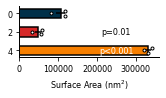

In [36]:
Rawdata = DATA / "Fig2D_data.parquet"
df_all = pd.read_parquet(Rawdata)

df_all = df_all[df_all['label'].isin(['G01','G02','G03','G21','G22','G23','G41','G42','G43',])]
df_all['label'] = df_all['label'].str[:-1]
df = df_all[['Surface area','label']].reset_index(drop=True)
df['Surface area'] = df['Surface area'].astype(float)
means, sems = df.groupby('label')['Surface area'].mean(), df.groupby('label')['Surface area'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'G2']['Surface area'],
                                  df[df['label'] == 'G4']['Surface area'],], 
                                  df[df['label'] == 'G0']['Surface area'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,0.9375))
people, y_pos = ('0','2','4',), [0,1,2,]
ax.barh(people, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'G0']['Surface area'], width=0.25)
ax.plot(df[df['label'] == 'G0']['Surface area'],x1, '.', label = 'D',
        color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'G2']['Surface area'], width=0.25)
ax.plot(df[df['label'] == 'G2']['Surface area'],x2+1,  '.', label = 'C9',
        color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'G4']['Surface area'], width=0.25)
ax.plot(df[df['label'] == 'G4']['Surface area'],x3+2,  '.', label = 'aH',
        color ='w',markeredgecolor='black')
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Surface Area (nm$^2$)',fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [200000,200000], 50000
label1 = f"p={p_values[0]:.2f}" ### p=0.016155 tt, p-dunnett=0.0117
label2 = r"p<0.001" ### p=0.000069 tt, p-dunnett=0.0000
ax.text(pvp[0] + pad,1, label1, fontsize=8, va="center", ha="center")
ax.text(pvp[1] + pad,2, label2, fontsize=8, color='w', va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2H.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

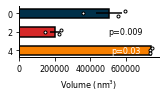

In [37]:
Rawdata = DATA / "Fig2D_data.parquet"
df_all = pd.read_parquet(Rawdata)

df_all = df_all[df_all['label'].isin(['G01','G02','G03','G21','G22','G23','G41','G42','G43',])]
df_all['label'] = df_all['label'].str[:-1]
df = df_all[['Volume','label']].reset_index(drop=True)
df['Volume'] = df['Volume'].astype(float)
means, sems = df.groupby('label')['Volume'].mean(), df.groupby('label')['Volume'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'G2']['Volume'],df[df['label'] == 'G4']['Volume'],], 
                                 df[df['label'] == 'G0']['Volume'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,0.9375))
people, y_pos = ('0','2','4',), [0,1,2,]
ax.barh(people, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'G0']['Volume'], width=0.25)
ax.plot(df[df['label'] == 'G0']['Volume'],x1, '.', label = 'D',color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'G2']['Volume'], width=0.25)
ax.plot(df[df['label'] == 'G2']['Volume'],x2+1,  '.', label = 'C9',color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'G4']['Volume'], width=0.25)
ax.plot(df[df['label'] == 'G4']['Volume'],x3+2,  '.', label = 'aH',color ='w',markeredgecolor='black')
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Volume (nm$^3$)',fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [550000,550000], 50000
label1 = f"p={p_values[0]:.3f}" ### p=0.017505 tt, p-dunnett=0.0093
label2 = f"p={p_values[1]:.2f}" ### p=0.032030 tt, p-dunnett=0.0302
ax.text(pvp[0] + pad,1, label1, fontsize=8, va="center", ha="center")
ax.text(pvp[1] + pad,2, label2, fontsize=8, color='w', va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2I.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

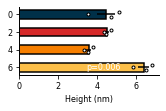

In [38]:
Rawdata = DATA / "Fig2K_data.parquet"
df_all = pd.read_parquet(Rawdata)
df_all['Average value'] = df_all['Average value'].astype(float)

# Separate the normal and 'nm' rows
normal = df_all[~df_all['label'].str.endswith('nm')].set_index('label')
nm     = df_all[df_all['label'].str.endswith('nm')].copy()
nm['label'] = nm['label'].str.replace('nm', '', regex=False)
nm = nm.set_index('label')
diff = normal['Average value'] - nm['Average value']
df = pd.DataFrame({'label': normal.index,
                   'normal': normal['Average value'],
                   'nm': nm['Average value'],
                   'difference': normal['Average value'] - nm['Average value']
                   }).reset_index(drop=True)

df['label'] = df['label'].str[:-1]
means, sems = df.groupby('label')['difference'].mean(), df.groupby('label')['difference'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'a2']['difference'],
                                  df[df['label'] == 'a4']['difference'],
                                  df[df['label'] == 'a6']['difference']], 
                                  df[df['label'] == 'a0']['difference'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,1.25))
people, y_pos = ('0','2','4','6'), [0,1,2,3]
ax.barh(y_pos, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'a0']['difference'], width=0.25)
ax.plot(df[df['label'] == 'a0']['difference'],x1, '.', label = 'D',color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'a2']['difference'], width=0.25)
ax.plot(df[df['label'] == 'a2']['difference'],x2+1,  '.', label = 'C9',color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'a4']['difference'], width=0.25)
ax.plot(df[df['label'] == 'a4']['difference'],x3+2,  '.', label = 'aH',color ='w',markeredgecolor='black')
x4 = simple_beeswarm2(df[df['label'] == 'a6']['difference'], width=0.25)
ax.plot(df[df['label'] == 'a6']['difference'],x4+3,  '.', label = 'aH',color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Height (nm)',fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp,  pad = [7.2,7.2,3.6], 0.7
label3 = f"p={p_values[2]:.3f}" ### p=0.025672 tt, p_dunnet=0.0063
ax.text(pvp[2] + pad,3,  label3, fontsize=8, color ="w", va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2K.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

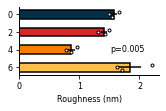

In [39]:
Rawdata = DATA / "Fig2K_data.parquet"
df_all = pd.read_parquet(Rawdata)

df_all = df_all[df_all['label'].isin(['a01','a02','a03','a21','a22','a23','a41','a42','a43',
                                          'a61','a62','a63'])]
df_all['label'] = df_all['label'].str[:-1]
df = df_all[['Mean roughness (Sa)','label']].reset_index(drop=True)
df['Mean roughness (Sa)'] = df['Mean roughness (Sa)'].astype(float)
means = df.groupby('label')['Mean roughness (Sa)'].mean()
sems = df.groupby('label')['Mean roughness (Sa)'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'a2']['Mean roughness (Sa)'],
                                  df[df['label'] == 'a4']['Mean roughness (Sa)'],
                                  df[df['label'] == 'a6']['Mean roughness (Sa)']], 
                                  df[df['label'] == 'a0']['Mean roughness (Sa)'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,1.25))
people, y_pos = ('0','2','4','6'), [0,1,2,3]
ax.barh(y_pos, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'a0']['Mean roughness (Sa)'], width=0.25)
ax.plot(df[df['label'] == 'a0']['Mean roughness (Sa)'],x1, '.', label = 'D',
        color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'a2']['Mean roughness (Sa)'], width=0.25)
ax.plot(df[df['label'] == 'a2']['Mean roughness (Sa)'],x2+1,  '.', label = 'C9',
        color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'a4']['Mean roughness (Sa)'], width=0.25)
ax.plot(df[df['label'] == 'a4']['Mean roughness (Sa)'],x3+2,  '.', label = 'aH',
        color ='w',markeredgecolor='black')
x4 = simple_beeswarm2(df[df['label'] == 'a6']['Mean roughness (Sa)'], width=0.25)
ax.plot(df[df['label'] == 'a6']['Mean roughness (Sa)'],x4+3,  '.', label = 'aH',
        color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Roughness (nm)',fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [2,1.8,2], 0
label2 = f"p={p_values[1]:.3f}" ### p=0.000610 tt, p-dunnett=0.0053
ax.text(pvp[1] + pad,2,  label2, fontsize=8, va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2L.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

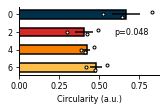

In [40]:
Rawdata = DATA / "Fig2M_data.parquet"
df = pd.read_parquet(Rawdata)

df = df.groupby('label')['Circ.'].describe().T
df = pd.DataFrame([(group, val) for group, vals in df.items() for val in vals[1:2]],
                  columns=['group', 'value'])
df['group'] = df['group'].str[1:-1]
means, sems = df.groupby('group')['value'].mean(), df.groupby('group')['value'].sem()

t_stats, p_values = dunnett_test([df[df['group'] == '2']['value'],df[df['group'] == '4']['value'],
                                  df[df['group'] == '6']['value']], 
                                  df[df['group'] == '0']['value'], alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,1.25))
people = ('0','2','4','6')
y_pos = [0,1,2,3]
ax.barh(y_pos, means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),linewidth=1.5,
        height=0.5)
x1 = simple_beeswarm2(df[df['group'] == '0']['value'], width=0.25)
ax.plot(df[df['group'] == '0']['value'],x1, '.', color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['group'] == '2']['value'], width=0.25)
ax.plot(df[df['group'] == '2']['value'],x2+1,  '.', color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['group'] == '4']['value'], width=0.25)
ax.plot(df[df['group'] == '4']['value'],x3+2,  '.', color ='w',markeredgecolor='black')
x4 = simple_beeswarm2(df[df['group'] == '6']['value'], width=0.25)
ax.plot(df[df['group'] == '6']['value'],x4+3,  '.',color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Circularity (a.u.)',fontsize=8)
# plt.xlim(2000, 17450)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp = [0.7,1,1]
label1 = f"p={p_values[0]:.3f}" ### p=0.000037 tt, p-Dunnett's=0.0004, p-Dunnett_triplicate=0.0484
label2 = r"ns" ### p=0.014237 tt, p-Dunnett's=0.0413,p-Dunnett_triplicate=0.0655
label3 = r"ns" ### p=0.002727 tt, p-Dunnett's=0.0135,p-Dunnett_triplicate=0.1985
pad = 0 
ax.text(pvp[0] + pad,1,  label1, fontsize=8, va="center", ha="center")
# ax.text(pvp[1] + pad,2,  label2, fontsize=8, va="center", ha="center")
# ax.text(pvp[1] + pad,3,  label3, fontsize=8, va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2M.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

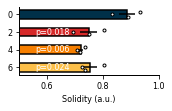

In [41]:
# ROOT, DATA = Path.cwd(), ROOT / "./DATA/"
Rawdata = DATA / "Fig2M_data.parquet"
df = pd.read_parquet(Rawdata)

df = df.groupby('label')['Solidity'].describe().T
df = pd.DataFrame([(group, val) for group, vals in df.items() for val in vals[1:2]],
                  columns=['group', 'value'])
df['group'] = df['group'].str[1:-1]
means, sems = df.groupby('group')['value'].mean(), df.groupby('group')['value'].sem()

t_stats, p_values = dunnett_test([df[df['group'] == '2']['value'],df[df['group'] == '4']['value'],
                                  df[df['group'] == '6']['value']], 
                                  df[df['group'] == '0']['value'], alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,1.25))
people, y_pos = ('0','2','4','6'), [0,1,2,3]
ax.barh(y_pos, means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),linewidth=1.5,
        height=0.5)
x1 = simple_beeswarm2(df[df['group'] == '0']['value'], width=0.25)
ax.plot(df[df['group'] == '0']['value'],x1, '.', color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['group'] == '2']['value'], width=0.25)
ax.plot(df[df['group'] == '2']['value'],x2+1,  '.', color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['group'] == '4']['value'], width=0.25)
ax.plot(df[df['group'] == '4']['value'],x3+2,  '.', color ='w',markeredgecolor='black')
x4 = simple_beeswarm2(df[df['group'] == '6']['value'], width=0.25)
ax.plot(df[df['group'] == '6']['value'],x4+3,  '.',color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Solidity (a.u.)',fontsize=8)
plt.xlim(0.5, 1)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp = [0.62,0.62,0.62]
label1 = f"p={p_values[0]:.3f}" ### p=0.000737 tt, p-dunnett=0.0062,p-dunnett_triplicate=0.0183
label2 = f"p={p_values[1]:.3f}" ### p=0.004383 tt, p-dunnett=0.0296,p-dunnett_triplicate=0.0061
label3 = f"p={p_values[2]:.3f}" ### p=0.000514 tt, p-dunnett=0.0056,p-dunnett_triplicate=0.0236
pad = 0
ax.text(pvp[0] + pad,1, label1, fontsize=8, color='w', va="center", ha="center")
ax.text(pvp[1] + pad,2, label2, fontsize=8,color='w', va="center", ha="center")
ax.text(pvp[1] + pad,3, label3, fontsize=8,color='w', va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2N.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

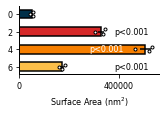

In [42]:
Rawdata = DATA / "Fig2K_data.parquet"
df_all = pd.read_parquet(Rawdata)

df_all = df_all[df_all['label'].isin(['a01','a02','a03','a21','a22','a23','a41','a42','a43',
                                          'a61','a62','a63'])]
df_all['label'] = df_all['label'].str[:-1]
df = df_all[['Surface area','label']].reset_index(drop=True)
df['Surface area'] = df['Surface area'].astype(float)
means, sems = df.groupby('label')['Surface area'].mean(), df.groupby('label')['Surface area'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'a2']['Surface area'],
                                  df[df['label'] == 'a4']['Surface area'],
                                  df[df['label'] == 'a6']['Surface area']], 
                                  df[df['label'] == 'a0']['Surface area'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,1.25))
people, y_pos = ('0','2','4','6'), [0,1,2,3]
ax.barh(y_pos, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'a0']['Surface area'], width=0.25)
ax.plot(df[df['label'] == 'a0']['Surface area'],x1, '.', label = 'D',
        color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'a2']['Surface area'], width=0.25)
ax.plot(df[df['label'] == 'a2']['Surface area'],x2+1,  '.', label = 'C9',
        color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'a4']['Surface area'], width=0.25)
ax.plot(df[df['label'] == 'a4']['Surface area'],x3+2,  '.', label = 'aH',
        color ='w',markeredgecolor='black')
x4 = simple_beeswarm2(df[df['label'] == 'a6']['Surface area'], width=0.25)
ax.plot(df[df['label'] == 'a6']['Surface area'],x4+3,  '.', label = 'aH',
        color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Surface Area (nm$^2$)',fontsize=8)
# plt.xlim(2000, 17450)
plt.xticks(fontsize=8)
ax.set_xticks(ax.get_xticks()[::2])
plt.yticks(fontsize=8)
pvp, pad = [450000,350000,450000], 0
label1 = r"p<0.001" ###p=0.000034 tt, p-dunnett=0.0000
label2 = r"p<0.001" ### p=0.000034 tt, p-dunnett=0.0000
label3 = r"p<0.001" ### p=0.000141 tt, p-dunnett=0.0008
ax.text(pvp[0] + pad,1,  label1, fontsize=8, va="center", ha="center")
ax.text(pvp[1] + pad,2,  label2, fontsize=8, color ='w',va="center", ha="center")
ax.text(pvp[2] + pad,3,  label3, fontsize=8,  va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2O.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()

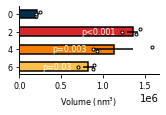

In [43]:
Rawdata = DATA / "Fig2K_data.parquet"
df_all = pd.read_parquet(Rawdata)

df_all = df_all[df_all['label'].isin(['a01','a02','a03','a21','a22','a23','a41','a42','a43',
                                          'a61','a62','a63'])]
df_all['label'] = df_all['label'].str[:-1]
df = df_all[['Volume','label']].reset_index(drop=True)
df['Volume'] = df['Volume'].astype(float)
means, sems = df.groupby('label')['Volume'].mean(), df.groupby('label')['Volume'].sem()

t_stats, p_values = dunnett_test([df[df['label'] == 'a2']['Volume'],df[df['label'] == 'a4']['Volume'],
                                  df[df['label'] == 'a6']['Volume']], df[df['label'] == 'a0']['Volume'], 
                                  alternative='two-sided')

fig, ax = plt.subplots(figsize=(2.5,1.25))
people, y_pos = ('0','2','4','6'), [0,1,2,3]
ax.barh(y_pos, width = means, xerr=sems, color=colorz, align='center',edgecolor=(0,0,0,1),
        linewidth=1.5,height=0.5)
x1 = simple_beeswarm2(df[df['label'] == 'a0']['Volume'], width=0.25)
ax.plot(df[df['label'] == 'a0']['Volume'],x1, '.', label = 'D',color ='w',markeredgecolor='black')
x2 = simple_beeswarm2(df[df['label'] == 'a2']['Volume'], width=0.25)
ax.plot(df[df['label'] == 'a2']['Volume'],x2+1,  '.', label = 'C9',color ='w',markeredgecolor='black')
x3 = simple_beeswarm2(df[df['label'] == 'a4']['Volume'], width=0.25)
ax.plot(df[df['label'] == 'a4']['Volume'],x3+2,  '.', label = 'aH',color ='w',markeredgecolor='black')
x4 = simple_beeswarm2(df[df['label'] == 'a6']['Volume'], width=0.25)
ax.plot(df[df['label'] == 'a6']['Volume'],x4+3,  '.', label = 'aH',color ='w',markeredgecolor='black')
ax.set_yticks(y_pos, labels=people)
ax.tick_params(top=False,bottom=True,left=True,right=False,labelleft=True,labelbottom=True)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Volume (nm$^3$)',fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
pvp, pad = [800000,450000,300000], 150000
label1 = r"p<0.001" ###p=0.000071 tt, p-dunnett=0.0007
label2 = f"p={p_values[1]:.3f}" ### p=0.015967 tt, p-dunnett=0.0030
label3 = f"p={p_values[2]:.2f}" ### p=0.000671 tt, p-dunnett=0.0311
ax.text(pvp[0] + pad,1,  label1, fontsize=8, color='w', va="center", ha="center")
ax.text(pvp[1] + pad,2,  label2, fontsize=8, color='w', va="center", ha="center")
ax.text(pvp[2] + pad,3,  label3, fontsize=8, color='w', va="center", ha="center")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(1)
ax.spines["left"].set_linewidth(1)
# outfile = FIGURES / "figure2P.svg"
# plt.savefig(outfile, format='svg', dpi=300, transparent=True,bbox_inches='tight')
plt.show()